##SoundScape AI
عندما يصبح للمشهد صوتً او عندما يصبح للصوت مشهد ؟؟


[Dataset](https://github.com/karolpiczak/esc-50)

In [ ]:
!git clone --depth 1 https://github.com/karoldvl/ESC-50.git

import pandas as pd

meta = pd.read_csv("ESC-50/meta/esc50.csv")
print("عدد المقاطع:", meta.shape[0])
print("عدد الفئات:", meta["category"].nunique())
display(meta.head())

# أسماء الفئات الموجودة فعلًا، للتأكد من أسمائها الدقيقة
print(sorted(meta["category"].unique()))

Cloning into 'ESC-50'...
remote: Enumerating objects: 2018, done.
remote: Counting objects: 100% (2018/2018), done.
remote: Compressing objects: 100% (1798/1798), done.
remote: Total 2018 (delta 215), reused 2009 (delta 214), pack-reused 0 (from 0)
Receiving objects: 100% (2018/2018), 615.62 MiB | 24.47 MiB/s, done.
Resolving deltas: 100% (215/215), done.
Updating files: 100% (2011/2011), done.
عدد المقاطع: 2000
عدد الفئات: 50


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind']


In [ ]:
import numpy as np
import librosa
import pandas as pd

rows = []
for _, r in processed.iterrows():
    y, _ = librosa.load(r["path"], sr=SR, mono=True)
    db = librosa.amplitude_to_db(librosa.feature.rms(y=y)[0], ref=1.0)
    rows.append({
        "category": r["category"],
        "silence_ratio": np.mean(db < -40),   # نسبة الإطارات الهادئة
        "loudness_db": db[db > -80].mean(),   # متوسط الشدة للأجزاء المسموعة
        "peak": np.abs(y).max(),              # قريب من 1 يعني احتمال clipping
    })

eda = pd.DataFrame(rows)
print(eda.groupby("category").agg(
    silence_mean=("silence_ratio", "mean"),
    silence_max=("silence_ratio", "max"),
    loud_mean=("loudness_db", "mean"),
    loud_std=("loudness_db", "std"),
    peak_max=("peak", "max"),
).round(3))

                silence_mean  silence_max  loud_mean  loud_std  peak_max
category                                                                
crackling_fire         0.319        0.975 -33.841000    12.069     1.000
crickets               0.368        1.000 -36.526001    10.776     0.732
insects                0.191        0.841 -31.042000     9.299     1.000
pouring_water          0.486        0.911 -38.546001     9.069     1.000
rain                   0.008        0.293 -22.791000     4.347     0.915
sea_waves              0.020        0.554 -22.093000     3.957     0.922
thunderstorm           0.155        0.732 -27.513000     8.804     1.000
wind                   0.000        0.000 -20.341999     6.332     1.000


In [ ]:
candidates = [
    "rain", "thunderstorm", "wind", "sea_waves", "pouring_water",
    "water_drops", "crickets", "insects", "chirping_birds",
    "crackling_fire", "engine", "crow", "church_bells"
]

counts = meta[meta["category"].isin(candidates)]["category"].value_counts()
print(counts)
print("المجموع:", counts.sum())
print(meta[meta["category"].isin(candidates)].groupby("fold").size())

category
chirping_birds    40
thunderstorm      40
crow              40
pouring_water     40
water_drops       40
church_bells      40
wind              40
crackling_fire    40
rain              40
insects           40
engine            40
sea_waves         40
crickets          40
Name: count, dtype: int64
المجموع: 520
fold
1    104
2    104
3    104
4    104
5    104
dtype: int64


In [ ]:
selected = [
    "rain", "thunderstorm", "wind", "sea_waves",
    "pouring_water", "crickets", "insects", "crackling_fire"
]

subset = meta[meta["category"].isin(selected)].copy()

train_df = subset[subset["fold"] != 5][["filename", "category", "target", "fold"]]
test_df = subset[subset["fold"] == 5][["filename", "category", "target", "fold"]]

print("التدريب:", len(train_df), "| الاختبار:", len(test_df))
print(subset.groupby("category").size())

train_df.to_csv("train_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)

التدريب: 256 | الاختبار: 64
category
crackling_fire    40
crickets          40
insects           40
pouring_water     40
rain              40
sea_waves         40
thunderstorm      40
wind              40
dtype: int64


In [ ]:
import os
import librosa
import soundfile as sf
import pandas as pd

SR = 16000
OUT_DIR = "processed_16k"
os.makedirs(OUT_DIR, exist_ok=True)

splits = {"train": "train_split.csv", "test": "test_split.csv"}
rows = []

for split, csv_path in splits.items():
    df = pd.read_csv(csv_path)
    for _, r in df.iterrows():
        src = os.path.join("ESC-50/audio", r["filename"])
        y, _ = librosa.load(src, sr=SR, mono=True)
        out_path = os.path.join(OUT_DIR, r["filename"])
        sf.write(out_path, y, SR)
        rows.append({
            "filename": r["filename"],
            "category": r["category"],
            "target": r["target"],
            "fold": r["fold"],
            "split": split,
            "duration": len(y) / SR,
            "path": out_path,
        })

processed = pd.DataFrame(rows)
processed.to_csv("processed_meta.csv", index=False)

print(processed.groupby("split").size())
print(processed["duration"].describe())
print("مقاطع مدتها ليست 5 ثوانٍ:", (abs(processed["duration"] - 5) > 0.01).sum())

split
test      64
train    256
dtype: int64
count    320.0
mean       5.0
std        0.0
min        5.0
25%        5.0
50%        5.0
75%        5.0
max        5.0
Name: duration, dtype: float64
مقاطع مدتها ليست 5 ثوانٍ: 0


أشكال الـ spectrograms: {(128, 313)}
المدى: min = -80.0 max = 0.0


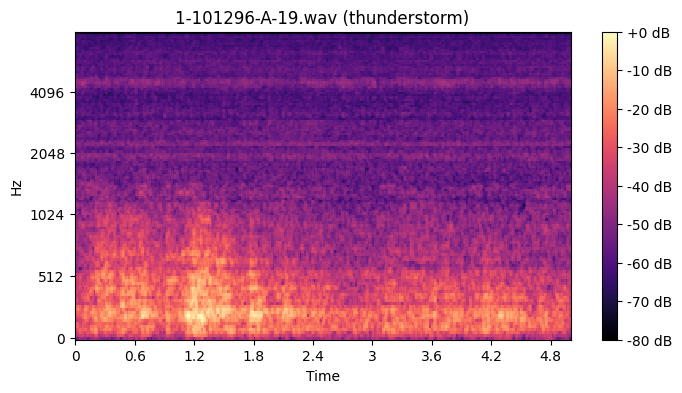

In [ ]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

N_FFT = 1024
HOP = 256
N_MELS = 128
FMAX = 8000

def to_logmel(path):
    y, sr = librosa.load(path, sr=SR, mono=True)
    mel = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmax=FMAX
    )
    return librosa.power_to_db(mel, ref=np.max)

processed = pd.read_csv("processed_meta.csv")
mels = {}
for _, r in processed.iterrows():
    mels[r["filename"]] = to_logmel(r["path"]).astype(np.float32)

shapes = {m.shape for m in mels.values()}
print("أشكال الـ spectrograms:", shapes)
print("المدى: min =", min(m.min() for m in mels.values()),
      "max =", max(m.max() for m in mels.values()))

first = processed.iloc[0]["filename"]
plt.figure(figsize=(8, 4))
librosa.display.specshow(mels[first], sr=SR, hop_length=HOP,
                         x_axis="time", y_axis="mel", fmax=FMAX)
plt.colorbar(format="%+2.0f dB")
plt.title(f"{first} ({processed.iloc[0]['category']})")
plt.show()

np.savez_compressed("logmels.npz", **mels)

In [ ]:
def normalize(m):
    return (m + 80.0) / 80.0  # يحوّل [-80, 0] إلى [0, 1]

files = processed["filename"].tolist()
X = np.stack([normalize(mels[f]) for f in files]).astype(np.float32)

floor_ratio = np.mean([(mels[f] <= -79.99).mean() for f in files])

print("شكل البيانات:", X.shape)
print("المدى بعد التطبيع: min =", X.min(), "max =", X.max())
print("نسبة البكسلات عند الحد الأدنى:", round(floor_ratio, 4))

شكل البيانات: (320, 128, 313)
المدى بعد التطبيع: min = 0.0 max = 1.0
نسبة البكسلات عند الحد الأدنى: 0.0438


In [ ]:
train_idx = processed.index[processed["split"] == "train"].values
test_idx = processed.index[processed["split"] == "test"].values

def pad_time(x, target=320):
    pad = target - x.shape[-1]
    return np.pad(x, ((0, 0), (0, 0), (0, pad)), constant_values=0.0)

X_train = pad_time(X[train_idx])[:, None, :, :]
X_test = pad_time(X[test_idx])[:, None, :, :]

y_train = processed.loc[train_idx, "target"].values
y_test = processed.loc[test_idx, "target"].values

np.savez_compressed("vae_data.npz",
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("أول فئة في التدريب والاختبار:", np.unique(y_train)[:5], np.unique(y_test)[:5])

X_train: (256, 1, 128, 320) | X_test: (64, 1, 128, 320)
y_train: (256,) | y_test: (64,)
أول فئة في التدريب والاختبار: [ 7 10 11 12 13] [ 7 10 11 12 13]


In [ ]:
print("تدريب:", np.unique(y_train))
print("اختبار:", np.unique(y_test))

تدريب: [ 7 10 11 12 13 16 17 19]
اختبار: [ 7 10 11 12 13 16 17 19]


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

CLASSES = sorted(np.unique(y_train).tolist())
cls2idx = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
LATENT = 32

def to_onehot(y):
    idx = torch.tensor([cls2idx[int(v)] for v in y])
    return F.one_hot(idx, NUM_CLASSES).float()

class CVAE(nn.Module):
    def __init__(self, latent=LATENT, n_cls=NUM_CLASSES):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2),    # 64x160
            nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),   # 32x80
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2), # 16x40
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2) # 8x20
        )
        flat = 256 * 8 * 20
        self.fc_mu = nn.Linear(flat + n_cls, latent)
        self.fc_lv = nn.Linear(flat + n_cls, latent)
        self.fc_dec = nn.Linear(latent + n_cls, flat)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),  # 16x40
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),    # 32x80
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(),     # 64x160
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid()                        # 128x320
        )

    def encode(self, x, c):
        h = torch.cat([self.enc(x).flatten(1), c], dim=1)
        return self.fc_mu(h), self.fc_lv(h)

    def reparam(self, mu, lv):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * lv)

    def decode(self, z, c):
        h = self.fc_dec(torch.cat([z, c], dim=1)).view(-1, 256, 8, 20)
        return self.dec(h)

    def forward(self, x, c):
        mu, lv = self.encode(x, c)
        z = self.reparam(mu, lv)
        return self.decode(z, c), mu, lv

def cvae_loss(recon, x, mu, lv, beta=1.0):
    n = x.size(0)
    rec = F.binary_cross_entropy(recon, x, reduction="sum") / n
    kld = -0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp()) / n
    return rec + beta * kld, rec, kld

# اختبار سريع للأشكال
model = CVAE()
xb = torch.tensor(X_train[:4])
cb = to_onehot(y_train[:4])
recon, mu, lv = model(xb, cb)
print("شكل الإخراج:", recon.shape)  # المتوقع (4, 1, 128, 320)
print("شكل mu:", mu.shape)          # المتوقع (4, 32)
loss, rec, kld = cvae_loss(recon, xb, mu, lv)
print("الخسارة:", loss.item(), "| rec:", rec.item(), "| kld:", kld.item())
print("عدد المعاملات:", sum(p.numel() for p in model.parameters()))

شكل الإخراج: torch.Size([4, 1, 128, 320])
شكل mu: torch.Size([4, 32])
الخسارة: 37384.3046875 | rec: 37380.203125 | kld: 4.102926731109619
عدد المعاملات: 5680769


In [ ]:
train_proc = processed[processed["split"] == "train"]

clip_stats = []
for _, r in train_proc.iterrows():
    y, _ = librosa.load(r["path"], sr=SR, mono=True)
    rms_db = librosa.amplitude_to_db(librosa.feature.rms(y=y)[0], ref=1.0)
    clip_stats.append({
        "filename": r["filename"],
        "category": r["category"],
        "silence_ratio": np.mean(rms_db < -40),
        "clipped_samples": int(np.sum(np.abs(y) > 0.99)),
    })

cs = pd.DataFrame(clip_stats)
print("مقاطع صمتها أكثر من 80%:")
print(cs[cs["silence_ratio"] > 0.8].sort_values("silence_ratio", ascending=False))
print("\nمقاطع فيها قص محتمل (عينات > 0.99):")
print(cs[cs["clipped_samples"] > 0].groupby("category").size())

مقاطع صمتها أكثر من 80%:
              filename        category  silence_ratio  clipped_samples
43    1-57316-A-13.wav        crickets       1.000000                0
44    1-57318-A-13.wav        crickets       1.000000                0
59    1-80840-A-13.wav        crickets       1.000000                0
60    1-80841-A-13.wav        crickets       1.000000                0
86   2-125821-A-13.wav        crickets       1.000000                0
83   2-110613-A-13.wav        crickets       1.000000                0
184  3-163607-B-13.wav        crickets       1.000000                0
227  4-171823-A-13.wav        crickets       1.000000                0
234  4-181362-A-13.wav        crickets       1.000000                0
132  3-104632-A-12.wav  crackling_fire       0.974522                0
135  3-104958-A-12.wav  crackling_fire       0.949045                0
9     1-17742-A-12.wav  crackling_fire       0.923567                0
52     1-7057-A-12.wav  crackling_fire       0.91719

In [ ]:
EXCLUDE_SILENT = 0.999   # صمت كامل تقريبًا
EXCLUDE_MOSTLY = 0.90    # صمت أكثر من 90%
EXCLUDE_CLIP = {"1-19501-A-7.wav"}

bad = cs[
    (cs["silence_ratio"] >= EXCLUDE_SILENT)
    | (cs["silence_ratio"] > EXCLUDE_MOSTLY)
    | (cs["filename"].isin(EXCLUDE_CLIP))
]["filename"].tolist()

print("مقاطع سيتم استبعادها من التدريب:", len(bad))

keep_train = processed[(processed["split"] == "train") & (~processed["filename"].isin(bad))]
print("المتبقي في التدريب حسب الفئة:")
print(keep_train.groupby("category").size())
print("إجمالي التدريب بعد الاستبعاد:", len(keep_train))

مقاطع سيتم استبعادها من التدريب: 17
المتبقي في التدريب حسب الفئة:
category
crackling_fire    27
crickets          23
insects           31
pouring_water     30
rain              32
sea_waves         32
thunderstorm      32
wind              32
dtype: int64
إجمالي التدريب بعد الاستبعاد: 239


In [ ]:
import numpy as np
import librosa
import pandas as pd

SR = 16000
N_FFT = 1024
HOP = 256
N_MELS = 128
FMAX = 8000
TARGET_T = 320

# قائمة التدريب النهائية بعد الاستبعاد، وقائمة الاختبار كما هي
keep_train_files = keep_train["filename"].tolist()
test_df = processed[processed["split"] == "test"].reset_index(drop=True)

def to_logmel_fixed(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmax=FMAX
    )
    # مرجع ثابت = 1.0، مع القص عند -80 dB
    db = librosa.power_to_db(mel, ref=1.0, amin=1e-10, top_db=80.0)
    return db.astype(np.float32)

def normalize(m):
    return (m + 80.0) / 80.0  # [-80, 0] -> [0, 1]

def pad_time(x, target=TARGET_T):
    pad = target - x.shape[-1]
    return np.pad(x, ((0, 0), (0, pad)), constant_values=0.0)

def build(df):
    arrs, ys = [], []
    for _, r in df.iterrows():
        m = normalize(to_logmel_fixed(r["path"]))
        arrs.append(pad_time(m))
        ys.append(r["target"])
    X = np.stack(arrs)[:, None, :, :].astype(np.float32)
    return X, np.array(ys)

train_df = processed[processed["filename"].isin(keep_train_files)].reset_index(drop=True)

X_train, y_train = build(train_df)
X_test, y_test = build(test_df)

np.savez_compressed("vae_data_fixed.npz",
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test,
                    train_files=np.array(train_df["filename"].tolist()),
                    test_files=np.array(test_df["filename"].tolist()))

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("المدى: min =", X_train.min(), "max =", X_train.max())
print("الفئات في التدريب:", np.unique(y_train))
print("الفئات في الاختبار:", np.unique(y_test))

X_train: (239, 1, 128, 320) | X_test: (64, 1, 128, 320)
y_train: (239,) | y_test: (64,)
المدى: min = -0.041128732 max = 1.4415531
الفئات في التدريب: [ 7 10 11 12 13 16 17 19]
الفئات في الاختبار: [ 7 10 11 12 13 16 17 19]


In [ ]:
over = []
for i, f in enumerate(train_df["filename"]):
    over.append((np.mean(X_train_raw[i] > 1.0) if 'X_train_raw' in globals() else None))

for name, X in [("التدريب", X_train), ("الاختبار", X_test)]:
    print(name,
          "| نسبة القيم فوق 0 dB:", round(float(np.mean(X > 1.0)), 4),
          "| نسبة القيم تحت -80 dB:", round(float(np.mean(X < 0.0)), 4))

X_train = np.clip(X_train, 0.0, 1.0)
X_test = np.clip(X_test, 0.0, 1.0)

print("المدى بعد القص: train =", X_train.min(), X_train.max(),
      "| test =", X_test.min(), X_test.max())

np.savez_compressed("vae_data_fixed.npz",
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test,
                    train_files=np.array(train_df["filename"].tolist()),
                    test_files=np.array(test_df["filename"].tolist()))

التدريب | نسبة القيم فوق 0 dB: 0.0 | نسبة القيم تحت -80 dB: 0.0
الاختبار | نسبة القيم فوق 0 dB: 0.0 | نسبة القيم تحت -80 dB: 0.0
المدى بعد القص: train = 0.0 1.0 | test = 0.0 1.0


In [ ]:
raw_train = np.stack([normalize(to_logmel_fixed(p)) for p in train_df["path"]])
per_clip = (raw_train > 1.0).mean(axis=(1, 2))
train_df = train_df.assign(over_ratio=per_clip)
print(train_df.groupby("category")["over_ratio"].agg(["mean", "max"]).round(4))

                  mean     max
category                      
crackling_fire  0.0153  0.0600
crickets        0.0073  0.0589
insects         0.0261  0.1727
pouring_water   0.0080  0.0617
rain            0.0625  0.2881
sea_waves       0.1469  0.2908
thunderstorm    0.0500  0.1360
wind            0.0990  0.3433


In [ ]:
def logmel_db(path, ref):
    y, _ = librosa.load(path, sr=SR, mono=True)
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmax=FMAX
    )
    # top_db=None حتى لا يقص القيم نسبيًا، ونرى القيم الخام
    return librosa.power_to_db(mel, ref=ref, amin=1e-10, top_db=None)

for ref in [1.0, 10.0, 100.0]:
    raw = np.stack([logmel_db(p, ref) for p in train_df["path"]])
    p999 = np.percentile(raw, 99.9)
    over = np.mean(raw > 0.0)
    under = np.mean(raw < -80.0)
    print(f"ref={ref:>6} | فوق 0 dB: {over:.4%} | تحت -80 dB: {under:.4%} | المئين 99.9: {p999:.1f}")
    del raw

ref=   1.0 | فوق 0 dB: 5.4806% | تحت -80 dB: 2.5996% | المئين 99.9: 18.7
ref=  10.0 | فوق 0 dB: 0.6995% | تحت -80 dB: 3.3717% | المئين 99.9: 8.7
ref= 100.0 | فوق 0 dB: 0.0743% | تحت -80 dB: 5.4335% | المئين 99.9: -1.3


In [ ]:
REF = 10.0

def pad_time(x, target=TARGET_T):
    pad = target - x.shape[-1]
    return np.pad(x, ((0, 0), (0, pad)), constant_values=0.0)

def build_final(df):
    arrs, over, under = [], [], []
    for p in df["path"]:
        m = logmel_db(p, REF)              # قيم خام بالمرجع 10
        over.append(np.mean(m > 0.0))
        under.append(np.mean(m < -80.0))
        m = np.clip((m + 80.0) / 80.0, 0.0, 1.0)
        arrs.append(pad_time(m))
    X = np.stack(arrs)[:, None, :, :].astype(np.float32)
    return X, float(np.mean(over)), float(np.mean(under))

X_train, tr_over, tr_under = build_final(train_df)
X_test, te_over, te_under = build_final(test_df)
y_train = train_df["target"].values
y_test = test_df["target"].values

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("المدى: train =", X_train.min(), X_train.max(),
      "| test =", X_test.min(), X_test.max())
print(f"قص التدريب: فوق 0 dB {tr_over:.4%} | تحت -80 dB {tr_under:.4%}")
print(f"قص الاختبار: فوق 0 dB {te_over:.4%} | تحت -80 dB {te_under:.4%}")
print("الفئات في التدريب:", np.unique(y_train))
print("الفئات في الاختبار:", np.unique(y_test))

np.savez_compressed("vae_data_ref10.npz",
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test,
                    train_files=np.array(train_df["filename"].tolist()),
                    test_files=np.array(test_df["filename"].tolist()))

X_train: (239, 1, 128, 320) | X_test: (64, 1, 128, 320)
y_train: (239,) | y_test: (64,)
المدى: train = 0.0 1.0 | test = 0.0 1.0
قص التدريب: فوق 0 dB 0.6995% | تحت -80 dB 3.3717%
قص الاختبار: فوق 0 dB 1.2202% | تحت -80 dB 1.5682%
الفئات في التدريب: [ 7 10 11 12 13 16 17 19]
الفئات في الاختبار: [ 7 10 11 12 13 16 17 19]


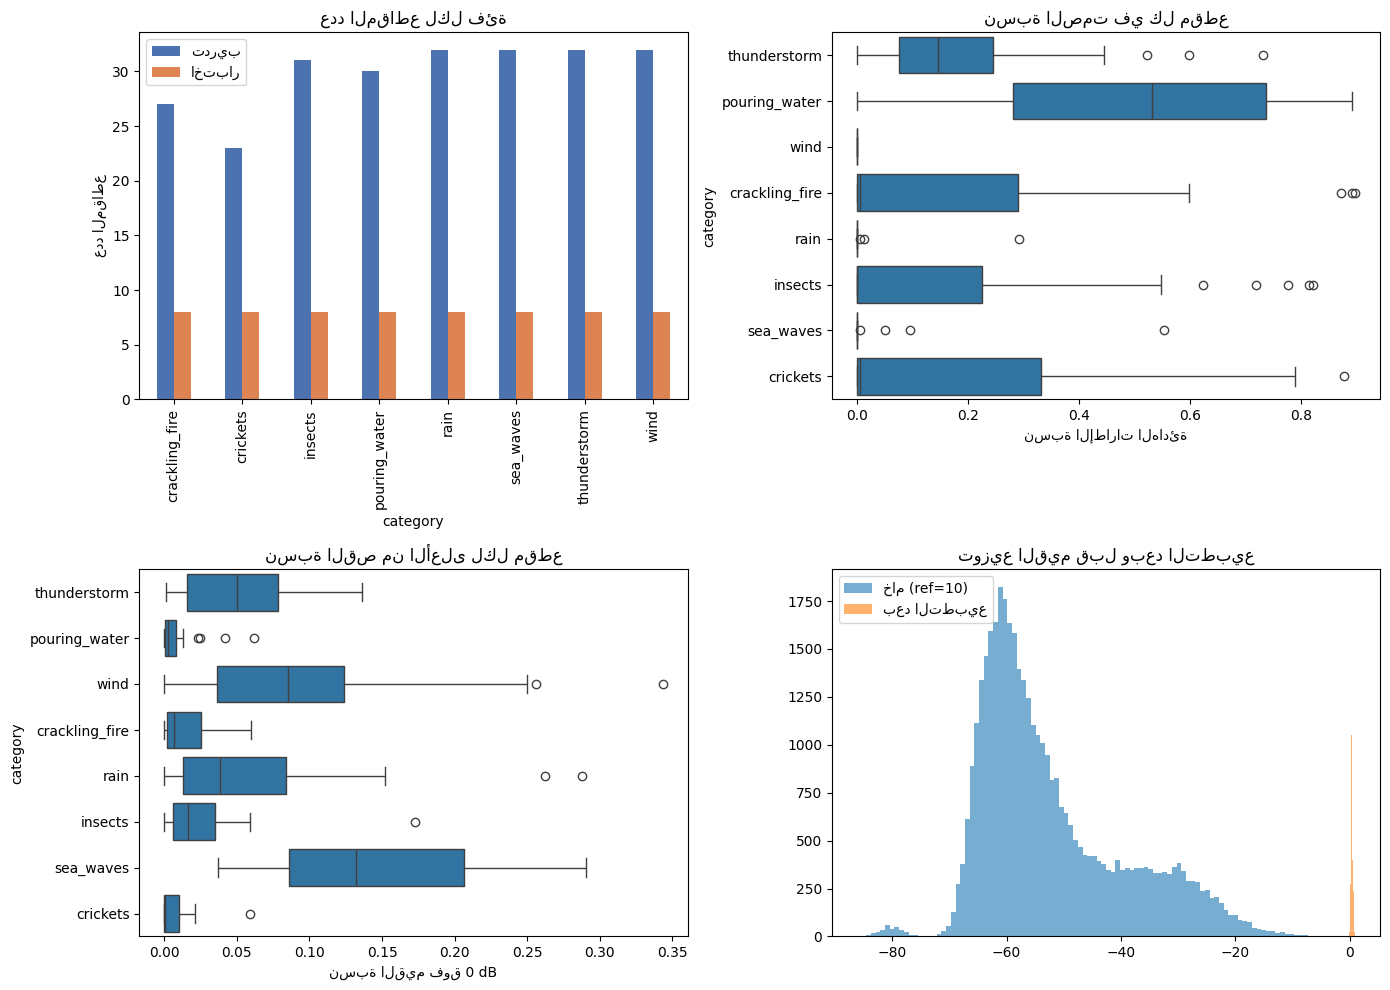

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. توزيع الفئات في التدريب والاختبار
counts = pd.DataFrame({
    "تدريب": train_df["category"].value_counts(),
    "اختبار": processed[processed["split"] == "test"]["category"].value_counts(),
}).fillna(0)
counts.plot(kind="bar", ax=axes[0, 0], color=["#4C72B0", "#DD8452"])
axes[0, 0].set_title("عدد المقاطع لكل فئة")
axes[0, 0].set_ylabel("عدد المقاطع")

# 2. نسبة الصمت لكل فئة (على مجموعة التدريب بعد الاستبعاد)
sns.boxplot(data=cs[cs["filename"].isin(keep_train_files)],
            x="silence_ratio", y="category", ax=axes[0, 1])
axes[0, 1].set_title("نسبة الصمت في كل مقطع")
axes[0, 1].set_xlabel("نسبة الإطارات الهادئة")

# 3. نسبة القص من الأعلى لكل فئة (للتدريب)
over_df = train_df.assign(over_ratio=per_clip)
sns.boxplot(data=over_df, x="over_ratio", y="category", ax=axes[1, 0])
axes[1, 0].set_title("نسبة القص من الأعلى لكل مقطع")
axes[1, 0].set_xlabel("نسبة القيم فوق 0 dB")

# 4. الشدة الخام لمقطع مثال مقابل بعد التطبيع
example = processed.iloc[0]
raw_db = logmel_db(example["path"], REF)
axes[1, 1].hist(raw_db.ravel(), bins=100, alpha=0.6, label="خام (ref=10)")
axes[1, 1].hist(((raw_db + 80) / 80).ravel(), bins=100, alpha=0.6, label="بعد التطبيع")
axes[1, 1].set_title("توزيع القيم قبل وبعد التطبيع")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

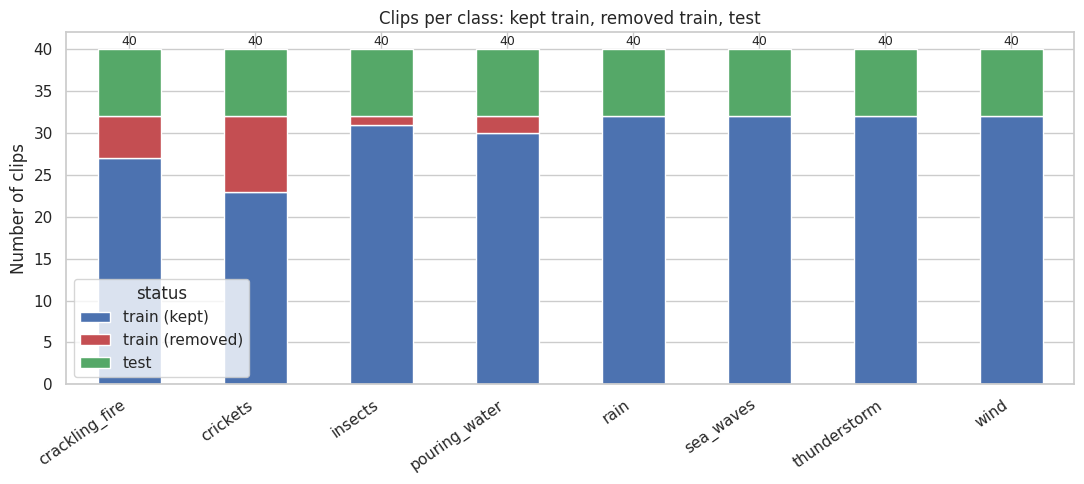

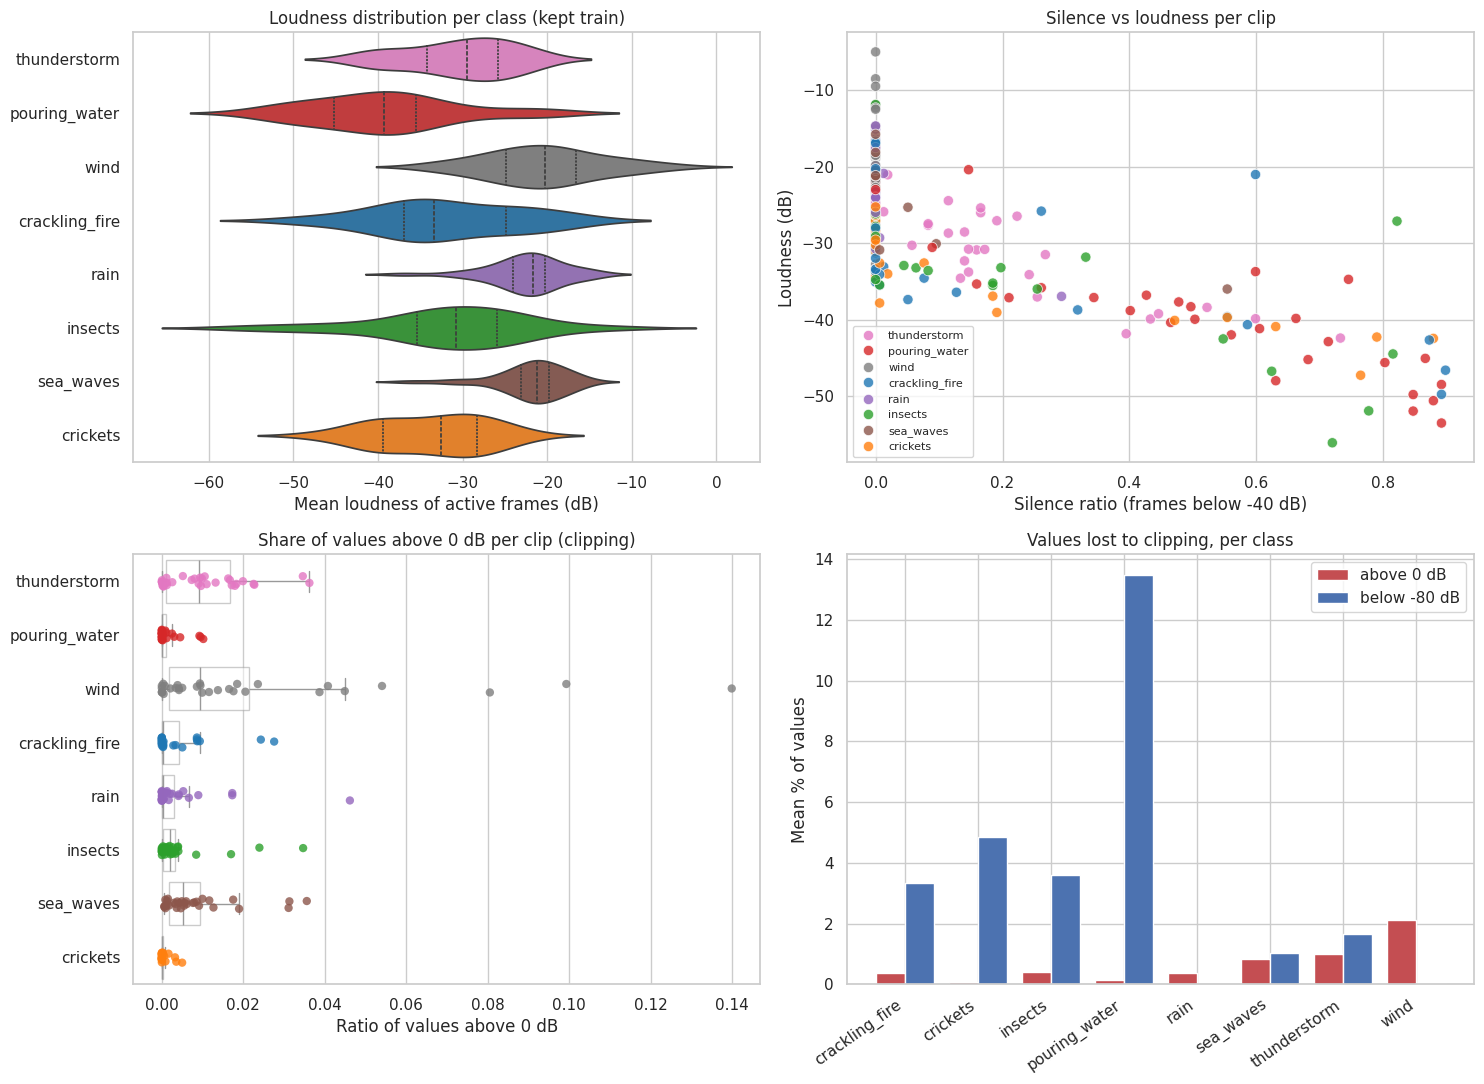

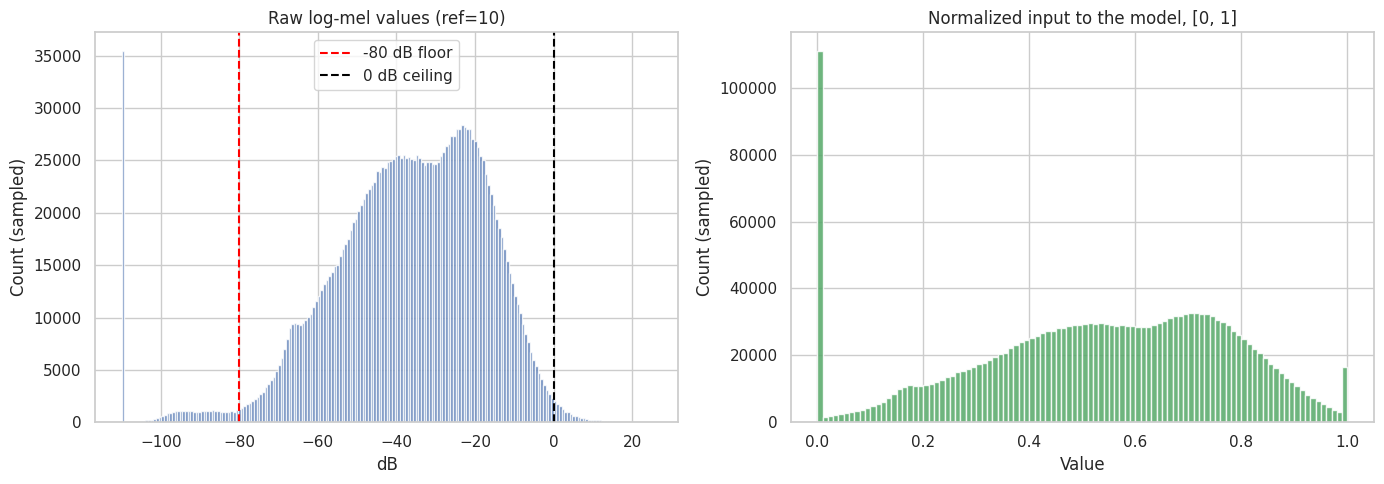

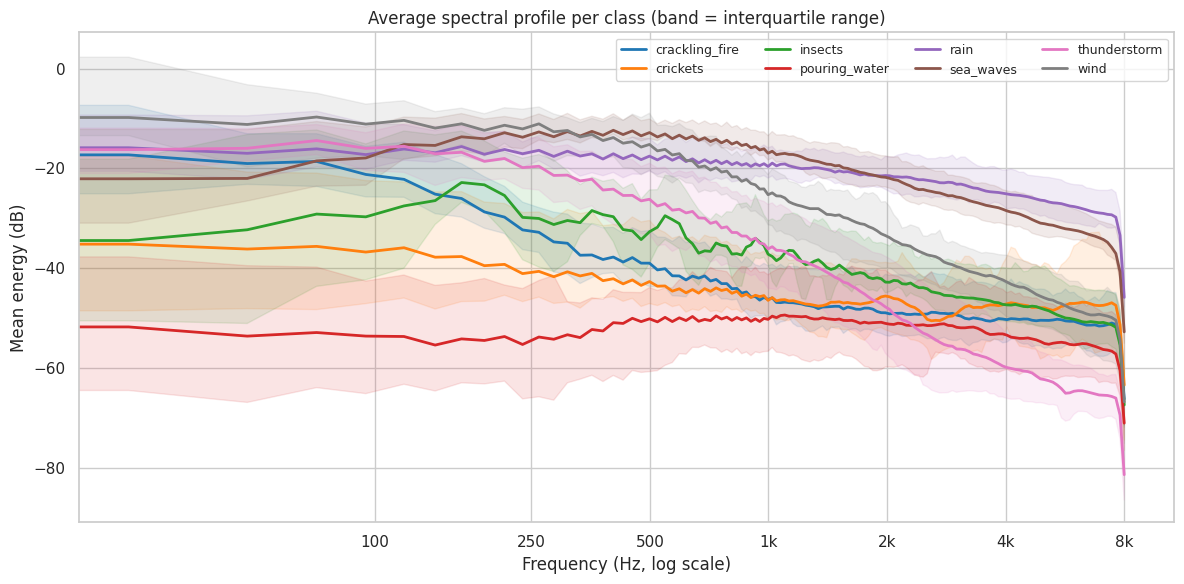

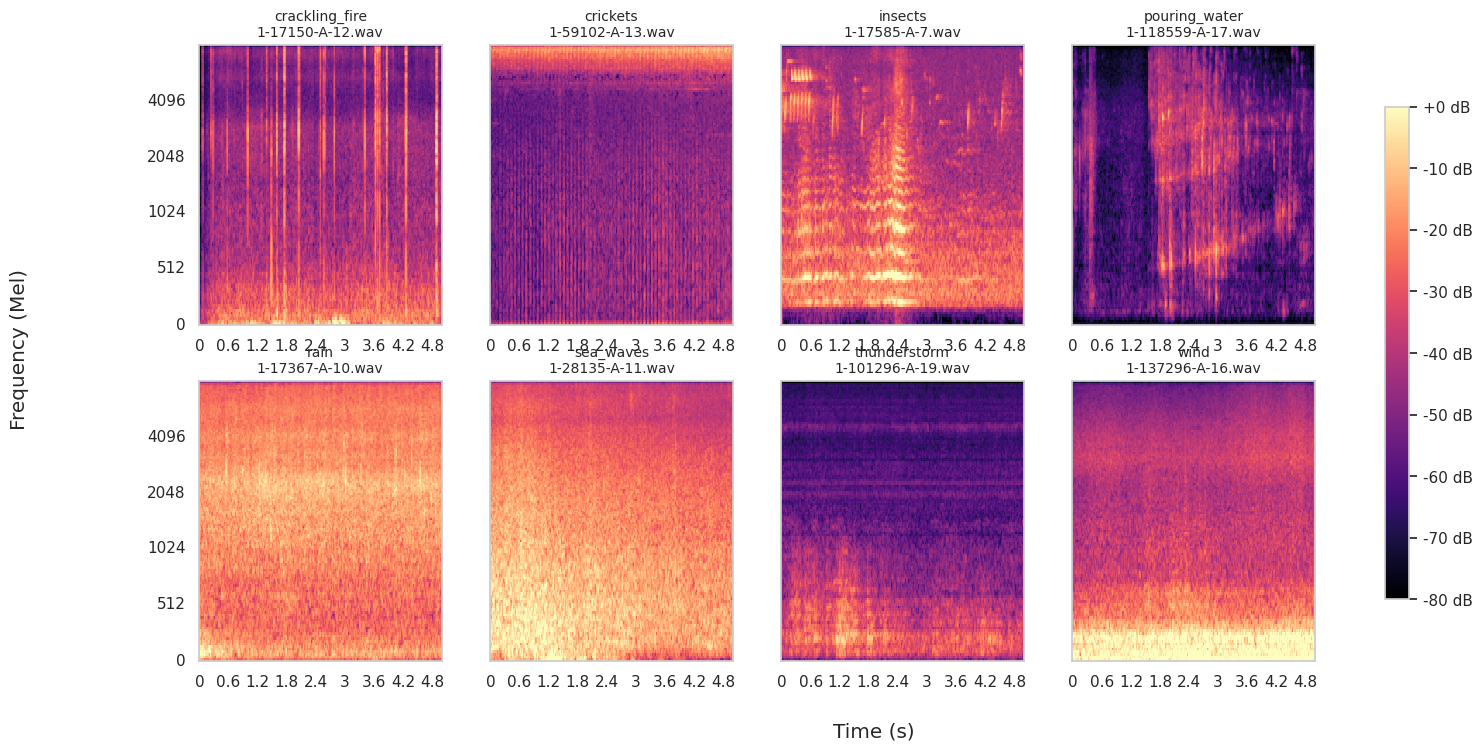

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

sns.set_theme(style="whitegrid", context="notebook")
cats = sorted(processed["category"].unique())
palette = dict(zip(cats, sns.color_palette("tab10", len(cats))))

# ---------- تجهيز الجداول ----------
proc = processed.reset_index(drop=True).copy()
proc["silence"] = eda["silence_ratio"].values
proc["loud_db"] = eda["loudness_db"].values
proc["kept"] = proc["filename"].isin(keep_train_files)

# القيم الخام بالمرجع REF لكل المقاطع، لحساب القص وأنماط الطيف
raws = {f: logmel_db(p, REF) for f, p in zip(proc["filename"], proc["path"])}
proc["over"] = [float(np.mean(raws[f] > 0.0)) for f in proc["filename"]]
proc["under"] = [float(np.mean(raws[f] < -80.0)) for f in proc["filename"]]

def status(r):
    if r["split"] == "test":
        return "test"
    return "train (kept)" if r["kept"] else "train (removed)"
proc["status"] = proc.apply(status, axis=1)

# ---------- الشكل 1: توزيع الفئات وما استُبعد ----------
fig, ax = plt.subplots(figsize=(11, 5))
tab = proc.groupby(["category", "status"]).size().unstack(fill_value=0)
tab = tab[["train (kept)", "train (removed)", "test"]]
tab.plot(kind="bar", stacked=True, ax=ax,
         color=["#4C72B0", "#C44E52", "#55A868"], edgecolor="white")
for i, (cat, row) in enumerate(tab.iterrows()):
    ax.text(i, row.sum() + 0.5, int(row.sum()), ha="center", fontsize=9)
ax.set_title("Clips per class: kept train, removed train, test")
ax.set_ylabel("Number of clips")
ax.set_xlabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("fig1_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- الشكل 2: الشدة والصمت والقص لكل فئة ----------
kept = proc[proc["kept"]]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (أ) توزيع الشدة لكل فئة
sns.violinplot(data=kept, x="loud_db", y="category", hue="category",
               palette=palette, legend=False, inner="quartile", ax=axes[0, 0])
axes[0, 0].set_title("Loudness distribution per class (kept train)")
axes[0, 0].set_xlabel("Mean loudness of active frames (dB)")
axes[0, 0].set_ylabel("")

# (ب) الصمت مقابل الشدة لكل مقطع
sns.scatterplot(data=kept, x="silence", y="loud_db", hue="category",
                palette=palette, s=55, alpha=0.8, ax=axes[0, 1])
axes[0, 1].set_title("Silence vs loudness per clip")
axes[0, 1].set_xlabel("Silence ratio (frames below -40 dB)")
axes[0, 1].set_ylabel("Loudness (dB)")
axes[0, 1].legend(fontsize=8, title="", loc="lower left")

# (ج) نسبة القص من الأعلى لكل مقطع
sns.stripplot(data=kept, x="over", y="category", hue="category",
              palette=palette, size=6, alpha=0.8, legend=False, ax=axes[1, 0])
sns.boxplot(data=kept, x="over", y="category", showfliers=False,
            color="white", ax=axes[1, 0], boxprops=dict(alpha=0.5))
axes[1, 0].set_title("Share of values above 0 dB per clip (clipping)")
axes[1, 0].set_xlabel("Ratio of values above 0 dB")
axes[1, 0].set_ylabel("")

# (د) القص من الأسفل مقابل القص من الأعلى لكل فئة
clip_summary = kept.groupby("category")[["over", "under"]].mean().reset_index()
x = np.arange(len(clip_summary))
axes[1, 1].bar(x - 0.2, clip_summary["over"] * 100, 0.4, label="above 0 dB", color="#C44E52")
axes[1, 1].bar(x + 0.2, clip_summary["under"] * 100, 0.4, label="below -80 dB", color="#4C72B0")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(clip_summary["category"], rotation=35, ha="right")
axes[1, 1].set_ylabel("Mean % of values")
axes[1, 1].set_title("Values lost to clipping, per class")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("fig2_loudness_silence_clipping.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- الشكل 3: قبل التطبيع وبعده ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

raw_train = np.concatenate([raws[f].ravel() for f in keep_train_files])
sample = np.random.default_rng(0).choice(raw_train, size=min(2_000_000, raw_train.size), replace=False)
axes[0].hist(sample, bins=200, color="#4C72B0", alpha=0.8)
axes[0].axvline(-80, color="red", ls="--", label="-80 dB floor")
axes[0].axvline(0, color="black", ls="--", label="0 dB ceiling")
axes[0].set_title(f"Raw log-mel values (ref={REF:g})")
axes[0].set_xlabel("dB")
axes[0].set_ylabel("Count (sampled)")
axes[0].legend()

xs = X_train.ravel()
xs = np.random.default_rng(1).choice(xs, size=min(2_000_000, xs.size), replace=False)
axes[1].hist(xs, bins=100, color="#55A868", alpha=0.85)
axes[1].set_title("Normalized input to the model, [0, 1]")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("Count (sampled)")

plt.tight_layout()
plt.savefig("fig3_normalization.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- الشكل 4: متوسط الطيف لكل فئة ----------
mel_freqs = librosa.mel_frequencies(n_mels=N_MELS, fmin=0, fmax=FMAX)
fig, ax = plt.subplots(figsize=(12, 6))
for cat in cats:
    files = kept[kept["category"] == cat]["filename"].tolist()
    profiles = np.stack([raws[f].mean(axis=1) for f in files])  # (clips, mels)
    mean_p = profiles.mean(axis=0)
    lo, hi = np.percentile(profiles, [25, 75], axis=0)
    ax.plot(mel_freqs, mean_p, label=cat, color=palette[cat], lw=2)
    ax.fill_between(mel_freqs, lo, hi, color=palette[cat], alpha=0.12)
ax.set_xscale("log")
ax.set_xticks([100, 250, 500, 1000, 2000, 4000, 8000])
ax.set_xticklabels(["100", "250", "500", "1k", "2k", "4k", "8k"])
ax.set_xlabel("Frequency (Hz, log scale)")
ax.set_ylabel("Mean energy (dB)")
ax.set_title("Average spectral profile per class (band = interquartile range)")
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.savefig("fig4_mean_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- الشكل 5: مثال Mel-Spectrogram لكل فئة بمقياس موحد ----------
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, cat in zip(axes.ravel(), cats):
    row = kept[kept["category"] == cat].iloc[0]
    img = librosa.display.specshow(raws[row["filename"]], sr=SR, hop_length=HOP,
                                   x_axis="time", y_axis="mel", fmax=FMAX,
                                   vmin=-80, vmax=0, cmap="magma", ax=ax)
    ax.set_title(f"{cat}\n{row['filename']}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.supxlabel("Time (s)")
fig.supylabel("Frequency (Mel)")
fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.8)
plt.savefig("fig5_spectrogram_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import librosa

mel_fb = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmax=FMAX)
empty = np.where(mel_fb.sum(axis=1) == 0)[0]
print("عدد الفلاتر الفارغة:", len(empty), "| أرقامها:", empty)

عدد الفلاتر الفارغة: 0 | أرقامها: []


In [ ]:
low_floor = {f: float(np.mean(raws[f] <= -109.9)) for f in proc["filename"]}
s = pd.Series(low_floor)
print("مقاطع فيها قيم أرضية:", int((s > 0).sum()), "من", len(s))
print(s[s > 0].sort_values(ascending=False).head(15))
print("النسبة الكلية:", round(float(s.mean()), 4))

مقاطع فيها قيم أرضية: 25 من 320
4-133895-A-7.wav     0.812849
1-19501-A-7.wav      0.705846
1-61221-A-17.wav     0.631714
3-157187-A-12.wav    0.591229
2-102414-G-17.wav    0.533422
1-67152-A-17.wav     0.533372
5-207781-A-17.wav    0.422274
3-127874-A-17.wav    0.334140
4-172377-A-17.wav    0.281075
4-164661-B-12.wav    0.260408
3-187710-A-11.wav    0.196361
4-130891-A-7.wav     0.184255
5-212734-A-17.wav    0.153030
1-79220-A-17.wav     0.146890
5-215634-A-17.wav    0.134759
dtype: float64
النسبة الكلية: 0.0189


In [ ]:
y, _ = librosa.load(proc.loc[proc["filename"] == "4-133895-A-7.wav", "path"].iloc[0], sr=SR, mono=True)
print("عدد العينات الصفرية:", int(np.sum(y == 0)), "من", len(y))

عدد العينات الصفرية: 65734 من 80000
